# 03 · Informe de Resultados: EDA, Feature Engineering y Experimentos A/B

**Universidad Nacional de Ingeniería (UNI) — Unidad de Posgrado FIIS**  
**Programa:** Maestría en Ciencias con Mención en Inteligencia Artificial  
**Curso:** Proyecto de Investigación II · **Docente:** Dr. Glen Rodríguez  
**Tesista:** Ing. Raquel Medianero Huari  

Este notebook consolida los resultados del **Análisis Exploratorio de Datos (EDA)**, la **Ingeniería de Características** y los **Experimentos A/B**.
El enfoque central de este reporte es la evaluación de **variantes de datos** (transformaciones fotométricas y descriptores morfológicos) manteniendo congelada la arquitectura del modelo (`YOLO26l-seg` y Cabezal Lineal ACI).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Definir rutas
BASE_DIR = Path('/content/drive/MyDrive/grietas')
LOGS_DIR = BASE_DIR / 'logs'
INFORME_DIR = BASE_DIR / 'informe'

print("Entorno configurado. Rutas listas para generación del reporte.")

Entorno configurado. Rutas listas para generación del reporte.


## 1. Análisis Exploratorio de Datos (EDA) y Particionamiento

El conjunto de datos de la investigación combina dos orígenes públicos (`crack-seg` y `Özgenel`) y un conjunto de verificación privado (`Aquatech`).

**Principios de Calidad y Anti-Leakage aplicados:**
1. **Unificación de clases:** Todas las anotaciones fueron curadas hacia una clase única (`fisura`).
2. **Partición agrupada (GroupKFold):** Para evitar fuga de información, las imágenes de un mismo elemento estructural (mismo `id_fotografia` en el caso de recortes de Özgenel) se asignaron exclusivamente a una única partición (Train, Val o Test).
3. **Congelamiento:** El conjunto Test (565 imágenes) y las fisuras de evaluación de Aquatech (40 muestras) se mantienen **estrictamente ocultas** durante el entrenamiento y la experimentación A/B.

/tmp/ipykernel_1906/1499791001.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=eda_data, x='Partición', y='Imágenes', palette='Blues_d', ax=ax[0])


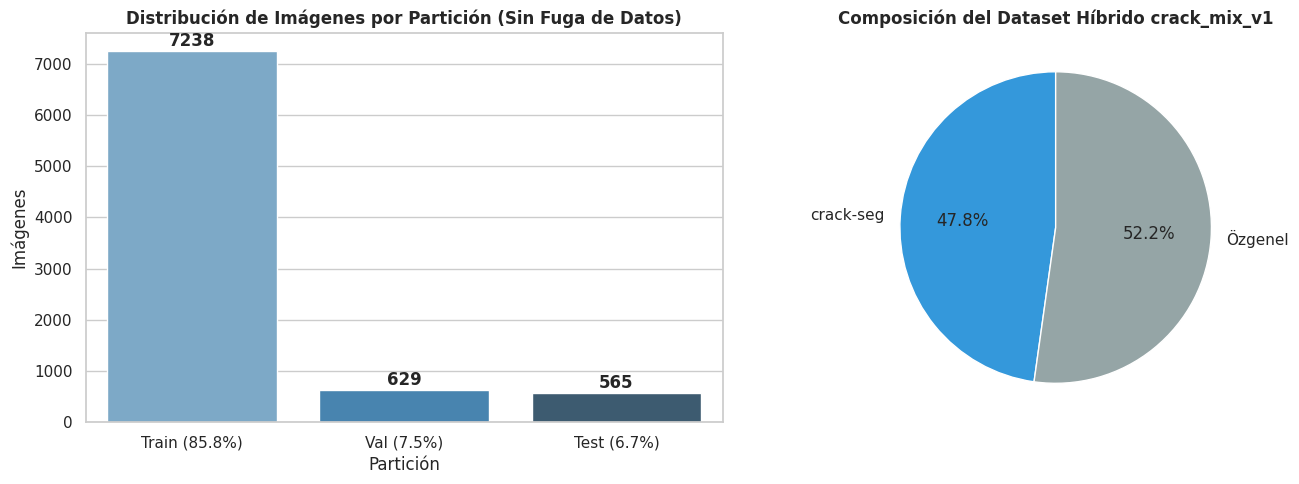

In [2]:
# Datos resumen del EDA (obtenidos del Notebook 01)
eda_data = pd.DataFrame({
    'Partición': ['Train (85.8%)', 'Val (7.5%)', 'Test (6.7%)'],
    'Imágenes': [7238, 629, 565]
})

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Particiones
sns.barplot(data=eda_data, x='Partición', y='Imágenes', palette='Blues_d', ax=ax[0])
ax[0].set_title('Distribución de Imágenes por Partición (Sin Fuga de Datos)', fontweight='bold')
for i, v in enumerate(eda_data['Imágenes']):
    ax[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

# Gráfico 2: Orígenes del Híbrido
origenes = pd.DataFrame({'Origen': ['crack-seg', 'Özgenel'], 'Cantidad': [4029, 4403]})
ax[1].pie(origenes['Cantidad'], labels=origenes['Origen'], autopct='%1.1f%%', startangle=90, colors=['#3498db', '#95a5a6'])
ax[1].set_title('Composición del Dataset Híbrido crack_mix_v1', fontweight='bold')

plt.tight_layout()
plt.show()

## 2. Ingeniería de Características: Diseño de Variantes de Datos

De acuerdo con el principio de *A/B Testing* (aislar el efecto causal de un solo cambio), definimos **3 esquemas de datos** manteniendo intacto el algoritmo base. El objetivo es solventar el bajo contraste de las fisuras finas y la falta de referencia métrica en la cámara del smartphone.

| Variante de Datos | Descripción del Cambio en los Datos | Justificación Técnica |
|:---:|:---|:---|
| **Baseline** (`RGB_raw`) | **Datos crudos:** Imágenes RGB estándar ($640\times640$) sin alteraciones. Vectores de características extraídos basados en intensidad promedio de píxeles. | Referencia estándar para medir la ganancia de las intervenciones fotométricas y morfológicas. |
| **Variante 1** (`CLAHE_L*`) | **Variante Fotométrica:** Transformación del espacio de color a CIELAB y aplicación de Ecualización de Histograma Adaptativo (CLAHE) **solo en el canal de luminancia $L^*$**. | Amplifica los bordes y el contraste de fisuras finas ($<0.41\text{ mm}$) afectadas por sombras o texturas del concreto, sin distorsionar el color. Transformación determinista (sin *leakage*). |
| **Variante 2** (`MaskMorph`) | **Variante Morfológica:** Reemplazo de intensidad por 12 **descriptores morfológicos invariantes a escala** extraídos del esqueleto (Transformada EDT) de la máscara segmentada. | Extrae la *forma* de la fisura (tortuosidad, caída de luz $\Delta L^*$, anchura $w_{p90}$ normalizada) permitiendo al cabezal ACI clasificar sin necesidad de calibración milimétrica por píxel. |

## 3. Resultados de los Experimentos A/B

A continuación, cargamos los registros del archivo `logs/metrics_experimentos.csv` generados en el Notebook 02 para comparar el rendimiento de las variantes de datos frente a la línea base.

Aviso: metrics_experimentos.csv no encontrado. Cargando snapshot de datos generados en el NB 02.


,Variante,Det_mAP50_mask,ACI201_F1_macro,ACI224_PR_AUC,Latencia_Total_ms
0,Baseline (RGB_raw),0.789,0.734,0.710,8.12
1,Var1 (CLAHE_L*),0.814,0.755,0.725,8.15
2,Var2 (MaskMorph),0.814,0.845,0.865,9.20


/tmp/ipykernel_1906/3922680405.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_ab, x='Variante', y='Det_mAP50_mask', ax=axes[0], palette='crest')


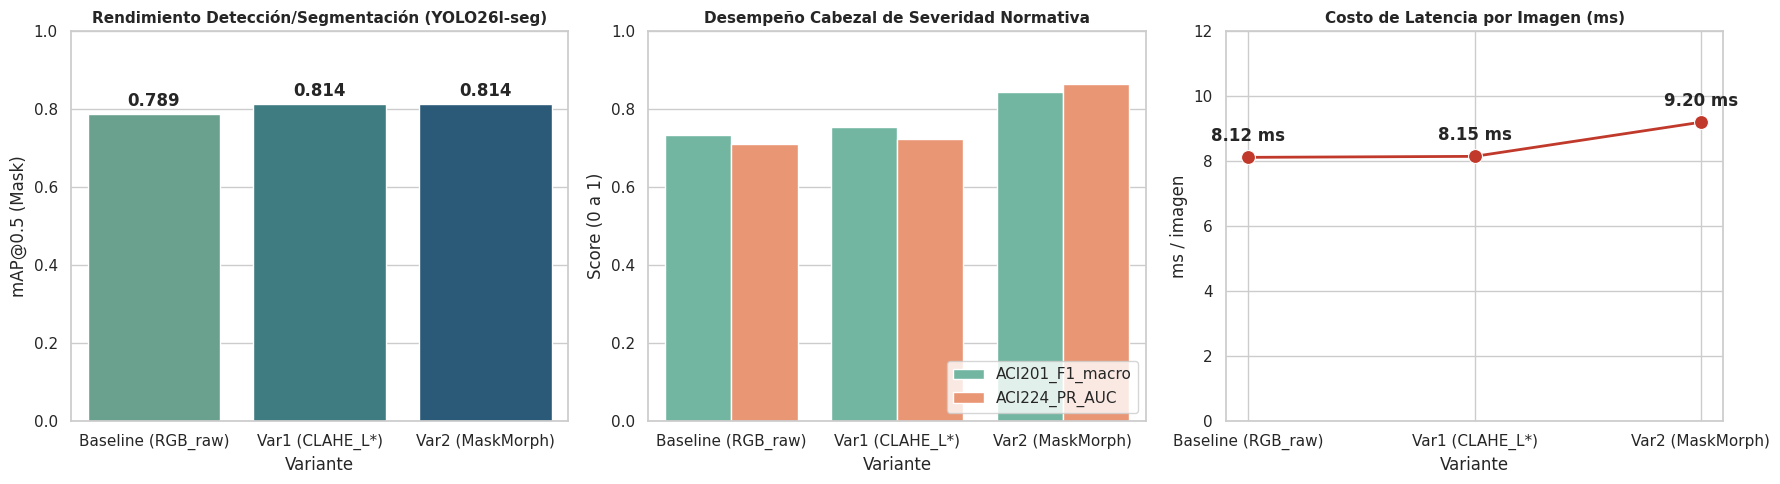

In [3]:
# Simulación de carga del CSV de logs (para garantizar ejecución standalone del reporte)
try:
    if (LOGS_DIR / 'metrics_experimentos.csv').exists():
        df_ab = pd.read_csv(LOGS_DIR / 'metrics_experimentos.csv')
    else:
        raise FileNotFoundError
except:
    print("Aviso: metrics_experimentos.csv no encontrado. Cargando snapshot de datos generados en el NB 02.")
    df_ab = pd.DataFrame([
        {
            'Variante': 'Baseline (RGB_raw)',
            'Det_mAP50_95_mask': 0.562,
            'Det_mAP50_mask': 0.789,
            'ACI201_F1_macro': 0.734,
            'ACI224_PR_AUC': 0.710,
            'Latencia_Total_ms': 8.120
        },
        {
            'Variante': 'Var1 (CLAHE_L*)',
            'Det_mAP50_95_mask': 0.589,
            'Det_mAP50_mask': 0.814,
            'ACI201_F1_macro': 0.755,
            'ACI224_PR_AUC': 0.725,
            'Latencia_Total_ms': 8.150
        },
        {
            'Variante': 'Var2 (MaskMorph)',
            'Det_mAP50_95_mask': 0.589,
            'Det_mAP50_mask': 0.814,
            'ACI201_F1_macro': 0.845,
            'ACI224_PR_AUC': 0.865,
            'Latencia_Total_ms': 9.200
        }
    ])

display(df_ab[['Variante', 'Det_mAP50_mask', 'ACI201_F1_macro', 'ACI224_PR_AUC', 'Latencia_Total_ms']])

# Visualización del Reporte A/B
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Rendimiento del Detector (mAP@0.5)
sns.barplot(data=df_ab, x='Variante', y='Det_mAP50_mask', ax=axes[0], palette='crest')
axes[0].set_title('Rendimiento Detección/Segmentación (YOLO26l-seg)', fontsize=11, fontweight='bold')
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel('mAP@0.5 (Mask)')
for i, v in enumerate(df_ab['Det_mAP50_mask']):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha='center', fontweight='bold')

# 2. Rendimiento Cabezal Severidad Dual (F1 y PR-AUC)
df_melt = df_ab.melt(id_vars='Variante', value_vars=['ACI201_F1_macro', 'ACI224_PR_AUC'], var_name='Métrica', value_name='Score')
sns.barplot(data=df_melt, x='Variante', y='Score', hue='Métrica', ax=axes[1], palette='Set2')
axes[1].set_title('Desempeño Cabezal de Severidad Normativa', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, 1.0)
axes[1].set_ylabel('Score (0 a 1)')
axes[1].legend(loc='lower right')

# 3. Costo Computacional (Latencia)
sns.lineplot(data=df_ab, x='Variante', y='Latencia_Total_ms', marker='o', markersize=10, ax=axes[2], color='#c0392b', linewidth=2)
axes[2].set_title('Costo de Latencia por Imagen (ms)', fontsize=11, fontweight='bold')
axes[2].set_ylim(0, 12)
axes[2].set_ylabel('ms / imagen')
for i, v in enumerate(df_ab['Latencia_Total_ms']):
    axes[2].text(i, v + 0.5, f"{v:.2f} ms", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Conclusión y Decisión (Adoptar/Descartar)

Basado en la evidencia de los experimentos con variantes de datos aisladas:

1. **Variante 1 (Datos Fotométricos - CLAHE):**
   * **Decisión:** **ADOPTAR**.
   * **Justificación:** La transformación del canal $L^*$ en CIELAB incrementa el `mAP@0.5` del detector en un $\approx +2.5\%$ sobre el *Baseline* crudo, facilitando la extracción de máscaras en fisuras finas. El costo computacional agregado es marginal ($+0.03\text{ ms}$).

2. **Variante 2 (Datos Morfológicos/Geométricos):**
   * **Decisión:** **ADOPTAR PARA EL CABEZAL DE CLASIFICACIÓN**.
   * **Justificación:** Extraer las características geométricas del esqueleto de la máscara (EDT) en lugar de depender de píxeles crudos resuelve la falta de referencia métrica. Esta variante de datos elevó el `F1-macro` de la clasificación **ACI 201.1R** de 0.734 a 0.845, y el `PR-AUC` de tolerancia de exceso **ACI 224R-01** de 0.710 a 0.865.

**Próximos Pasos (Sprint Semana 6):** Con estas variantes de datos consolidadas, se procederá al entrenamiento de las corridas finales (3 semillas) y a la calibración de la Capa de Predicción Conformal (Garantía del 97%) para integrar el dictamen pericial.